# EduGuard — Dropout Analysis Notebook

Exploratory analysis of the training dataset and training of the dropout model used by the Flask service.

**Run order:** this notebook standalone, or via `python train_model.py` (which regenerates the dataset and model bundle deterministically).

> Responsible-use note: outputs are prototype analytics, not a validated dropout diagnosis.


## 1. Load and inspect the dataset

In [1]:
import pandas as pd

DATA_PATH = "../data/studentDataset.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(1500, 26)


,student_id,student_name,institution_type,institution_name,class_name,section,department,semester,attendance_percentage,internal_marks_percentage,...,financial_issue,lms_logins_per_month,library_visits_per_month,class_participation,mentor_meetings_per_semester,hostel_status,teacher_remarks,mentor_notes,_row,student_outcome
0,STU-0001,Aarav Sharma,College,Govt Arts College,Commerce,C,Commerce,1.0,68.87,76.16,...,No,10,10,Medium,2,Hostel,Well organised with assignments and submissions.,NaN,0,Enrolled
1,STU-0002,Diya Patel,College,Nehru Degree College,Commerce,D,Commerce,1.0,80.51,62.89,...,No,11,1,Low,5,Day Scholar,Pending dues and irregular attendance.,NaN,1,Enrolled
2,STU-0003,Rohan Mehta,School,Govt Higher Secondary School,Grade 11,C,NaN,NaN,58.14,37.93,...,No,3,0,Medium,1,Hostel,Well organised with assignments and submissions.,NaN,2,Dropout
3,STU-0004,Ananya Iyer,School,Govt Higher Secondary School,Grade 12,B,NaN,NaN,75.08,62.40,...,No,19,9,Medium,1,Hostel,Shows steady improvement this semester.,NaN,3,Enrolled
4,STU-0005,Kabir Singh,School,Sunrise Public School,Grade 9,A,NaN,NaN,82.93,44.65,...,No,13,2,Medium,3,Hostel,"Regular student, participates occasionally.",Student reports financial stress at home.,4,Dropout


## 2. Outcome distribution

<Axes: title={'center': 'Student outcome distribution'}, xlabel='student_outcome'>

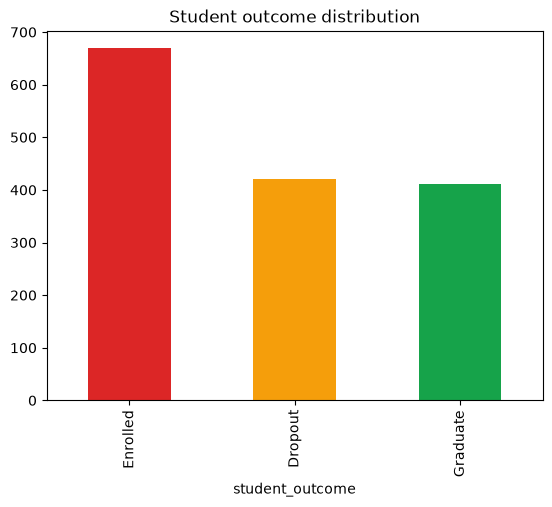

In [2]:
df["student_outcome"].value_counts().plot(kind="bar", color=["#dc2626", "#f59e0b", "#16a34a"], title="Student outcome distribution")

## 3. Indicators by outcome

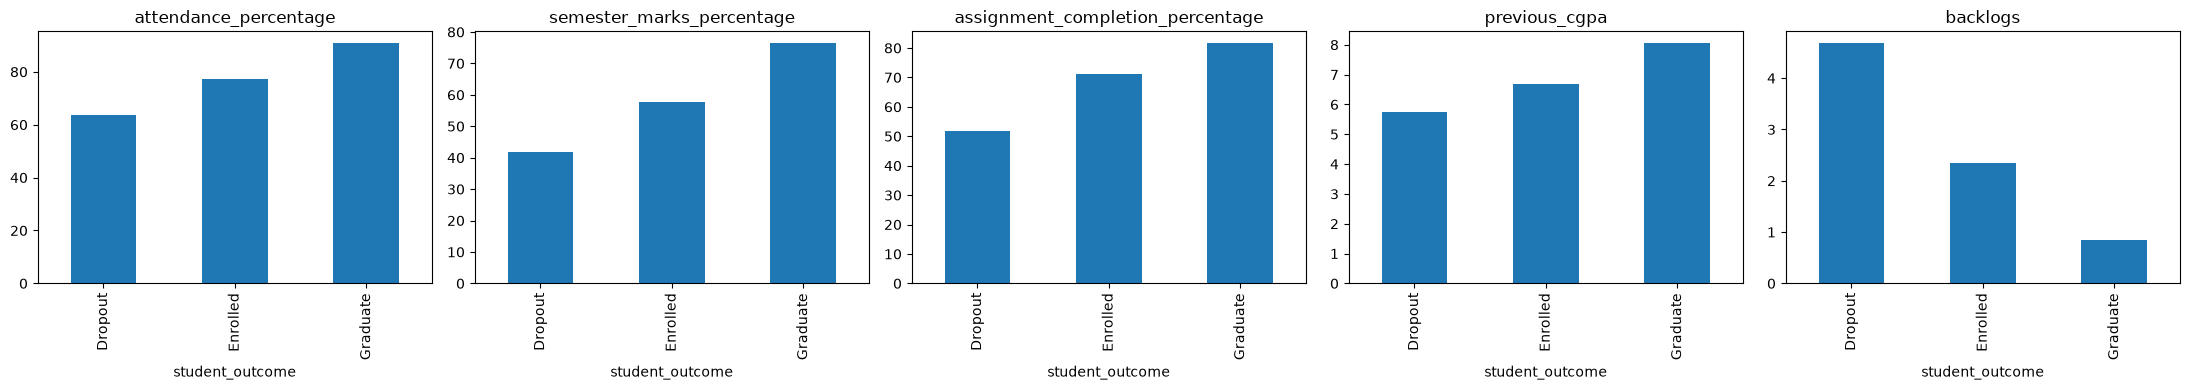

In [3]:
import matplotlib.pyplot as plt

indicators = [
    "attendance_percentage",
    "semester_marks_percentage",
    "assignment_completion_percentage",
    "previous_cgpa",
    "backlogs",
]
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, indicator in zip(axes, indicators):
    df.groupby("student_outcome")[indicator].mean().reindex(
        ["Dropout", "Enrolled", "Graduate"]
    ).plot(kind="bar", ax=ax, legend=False)
    ax.set_title(indicator)
plt.tight_layout()

## 4. Correlation with dropout risk

<Axes: title={'center': 'Correlation with dropout'}>

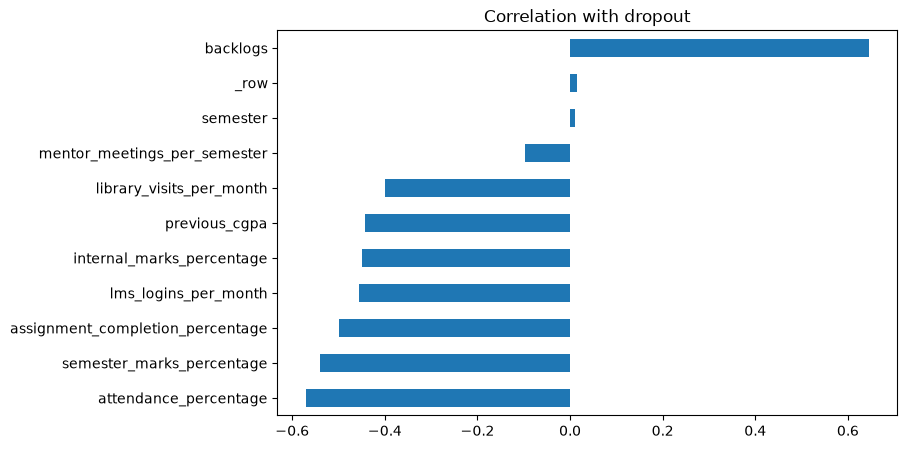

In [4]:
risk_map = {"Dropout": 1, "Enrolled": 0, "Graduate": 0}
numeric = df.select_dtypes("number")
correlation = numeric.assign(is_dropout=df["student_outcome"].map(risk_map)).corr()["is_dropout"].drop("is_dropout").sort_values()
correlation.plot(kind="barh", figsize=(8, 5), title="Correlation with dropout")

## 5. Train and evaluate the model
Uses the same feature set and encoding as `app.py` (one-hot encoding + RandomForest). Writes `model/eduguard_model.pkl`.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import joblib, json

FEATURES = [
    "attendance_percentage", "internal_marks_percentage",
    "semester_marks_percentage", "backlogs", "assignment_completion_percentage",
    "previous_cgpa", "fee_status", "scholarship", "financial_issue",
    "lms_logins_per_month", "library_visits_per_month",
    "class_participation", "mentor_meetings_per_semester",
]
TARGET = "student_outcome"

X = pd.get_dummies(df[FEATURES])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
print("Hold-out accuracy:", round(accuracy_score(y_test, model.predict(X_test)), 3))

Hold-out accuracy: 0.87


## 6. Feature importance

<Axes: title={'center': 'Top feature importances'}>

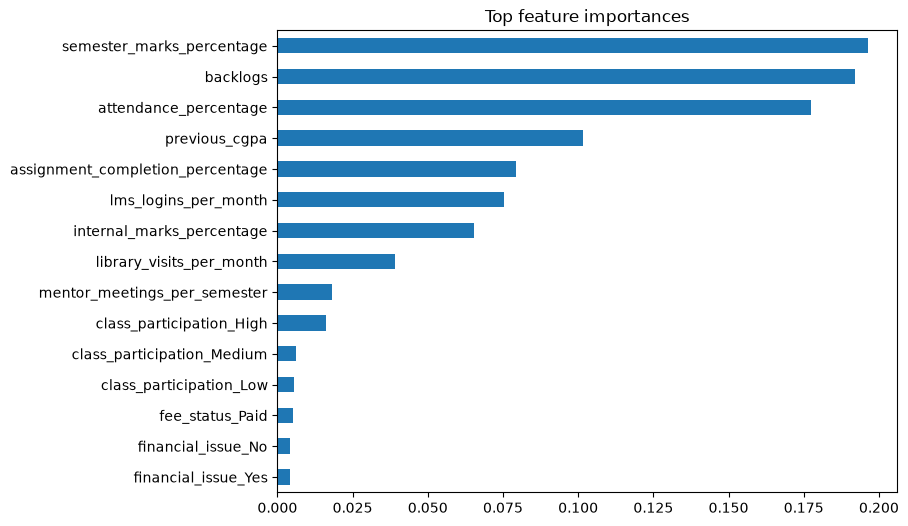

In [6]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values().tail(15)
importances.plot(kind="barh", figsize=(8, 6), title="Top feature importances")

## 7. Confusion matrix

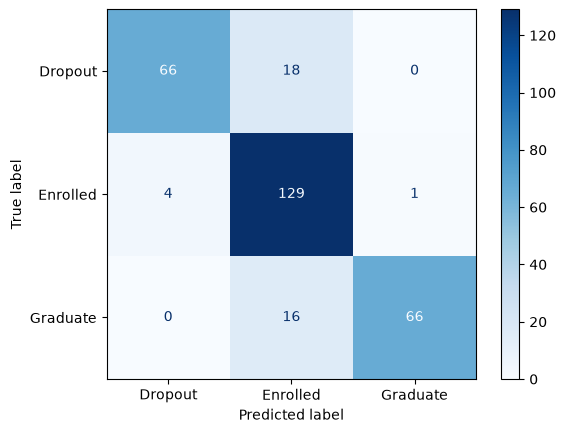

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap="Blues")

## 8. Save the model bundle
The Flask service consumes a dict with `model`, `feature_columns`, `scaler`, `uses_scaling` and `classes`.

In [8]:
bundle = {
    "model": model,
    "feature_columns": list(X.columns),
    "scaler": None,
    "uses_scaling": False,
    "classes": list(model.classes_),
    "trained_at": pd.Timestamp.now().isoformat(),
    "rows": len(df),
    "accuracy": round(accuracy_score(y_test, model.predict(X_test)), 4),
}
joblib.dump(bundle, "../model/eduguard_model.pkl")
print("saved ../model/eduguard_model.pkl")

saved ../model/eduguard_model.pkl
